# Introduction to Matplotlib

## Learning objectives

By the end of this notebook you will be able to:

- explain why visualisation matters in data analysis
- describe the main principles of a good chart
- understand Matplotlib's structure: Figure, Axes and artists
- use both the pyplot and the object-oriented interfaces

## Introduction

A chart can show in seconds what a table hides: skew, outliers, a trend, a difference between groups.
Matplotlib is Python's foundational plotting library. Seaborn and pandas' own plotting are built on it,
so knowing Matplotlib lets you adjust any Python chart.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAW = "../datasets/raw/"

## Why visualise? Anscombe's quartet

Four datasets with almost identical means, variances and correlations, but completely different
patterns. Summary statistics alone would call them the same.

In [2]:
x = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5])
x4 = np.array([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8])
ys = {
    "I":   (x,  [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x,  [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x,  [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  (x4, [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
for name, (xx, yy) in ys.items():
    yy = np.array(yy)
    print(f"{name:>3}: mean y {yy.mean():.2f}, sd y {yy.std(ddof=1):.2f}, r {np.corrcoef(xx, yy)[0, 1]:.3f}")

  I: mean y 7.50, sd y 2.03, r 0.816
 II: mean y 7.50, sd y 2.03, r 0.816
III: mean y 7.50, sd y 2.03, r 0.816
 IV: mean y 7.50, sd y 2.03, r 0.817


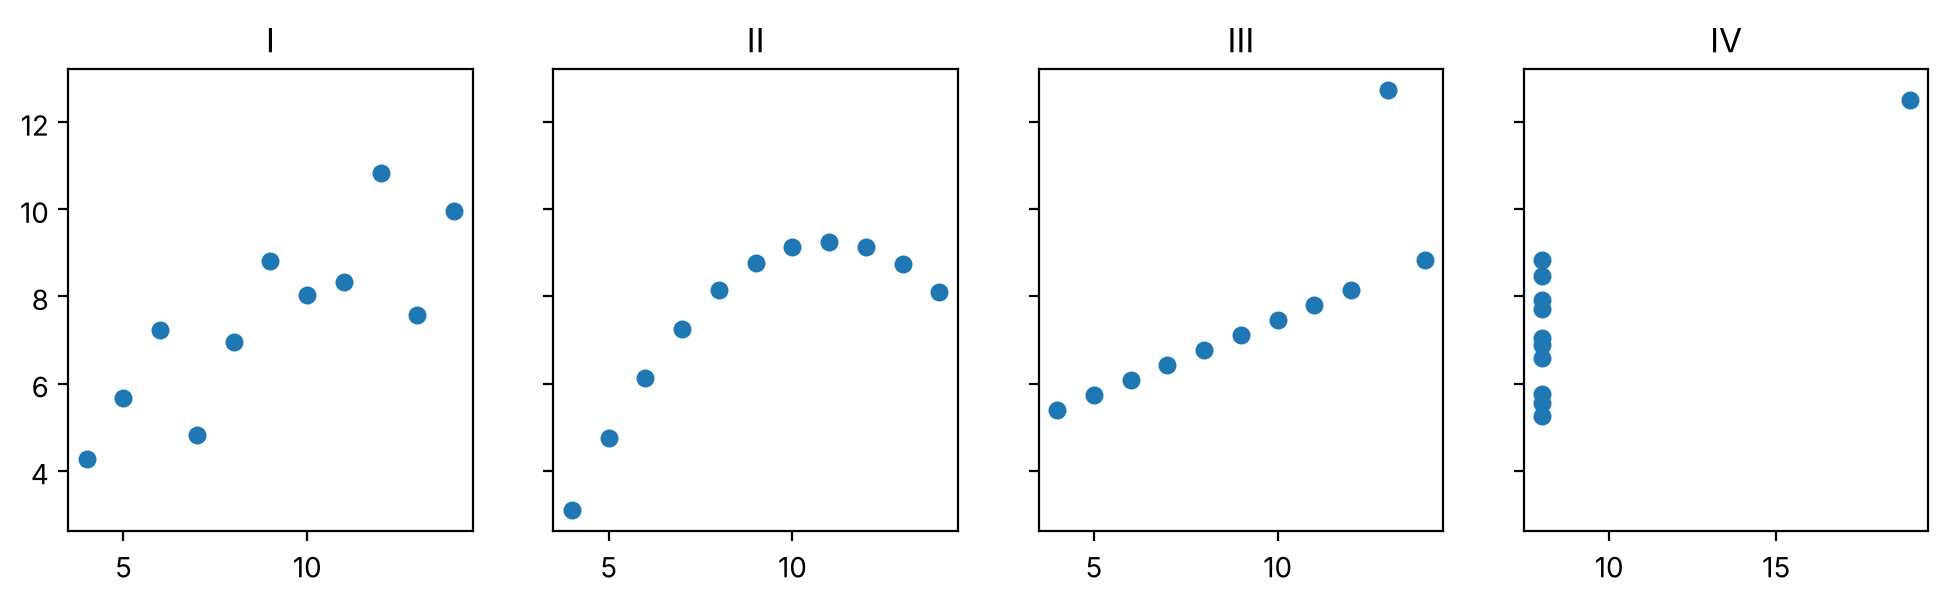

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, (name, (xx, yy)) in zip(axes, ys.items()):
    ax.scatter(xx, yy, s=30)
    ax.set_title(name)
plt.show()

## Principles of a good chart

1. **One message.** Decide what the chart should show, then choose the form: distribution (histogram,
   box plot), comparison of groups (bar, box), relationship (scatter), change over time (line).
2. **Honest scales.** Bar charts start at zero, because bar length encodes the value. Never use two
   different y-axes on one chart: readers compare the lines' heights, which then mean nothing. Draw two
   charts instead.
3. **Label everything.** A title that states the point, axis labels with units, a legend when there are
   two or more series.
4. **Colour with a purpose.** Colour for identity (groups) or magnitude (light to dark). Use
   colour-blind-friendly palettes such as `viridis` or `tab10`; avoid rainbow maps such as `jet`.
   Never rely on colour alone: add labels, markers or line styles.
5. **Remove clutter.** Light gridlines, no 3-D effects, no unnecessary borders.

## Matplotlib's structure

```
Figure  (the whole image, can hold several plots)
└── Axes  (one plot: the data area plus its x and y axis)
    ├── lines, markers, bars, text ... (artists)
    ├── XAxis / YAxis  (ticks, tick labels, axis label)
    └── title, legend
```

An **Axes** is a single plot, not the plural of axis. A figure with four panels has four Axes.

## Two interfaces

**pyplot** (`plt.plot`, `plt.title`): quick, works on the "current" plot.

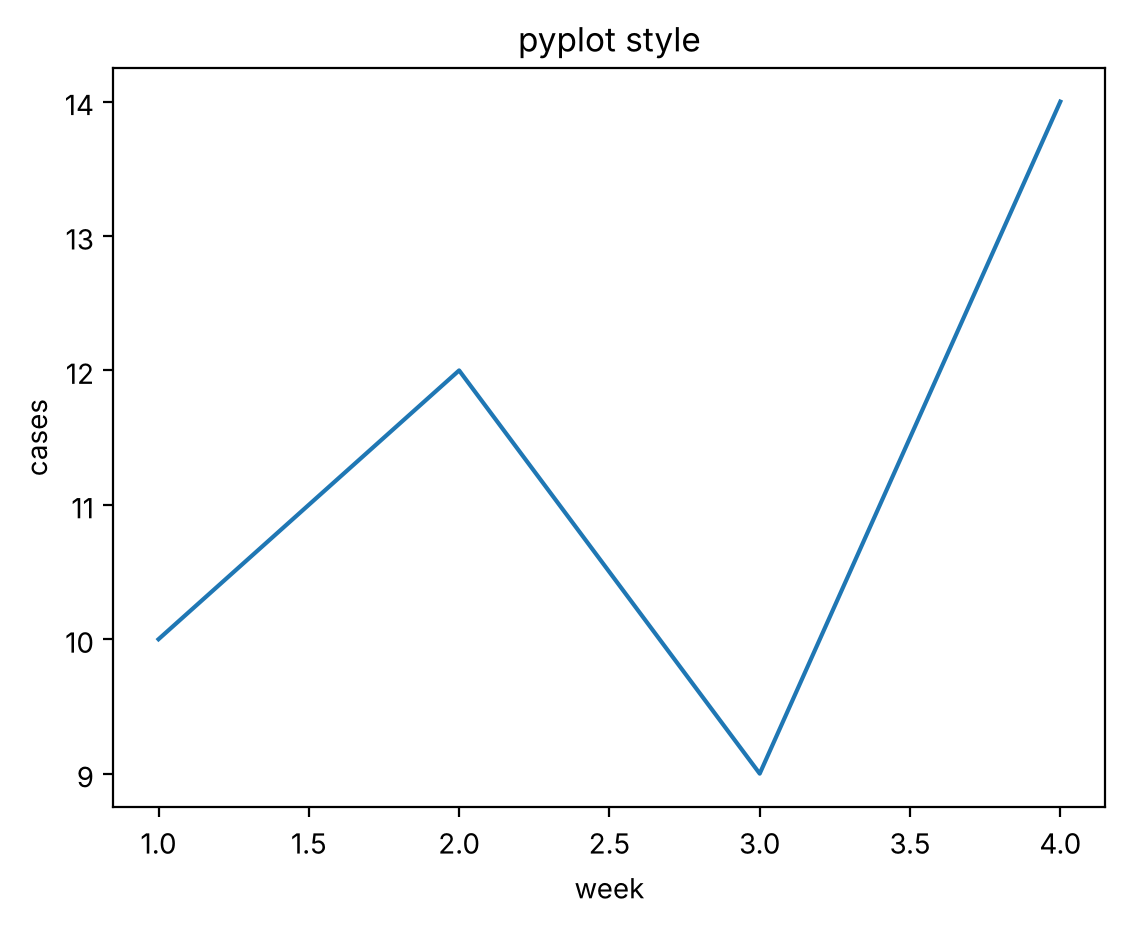

In [4]:
plt.plot([1, 2, 3, 4], [10, 12, 9, 14])
plt.title("pyplot style")
plt.xlabel("week")
plt.ylabel("cases")
plt.show()

**Object-oriented** (`fig, ax = plt.subplots()`, then `ax.plot`): you hold the Figure and Axes
explicitly. This is the recommended style, especially with several plots, and the one this course uses.

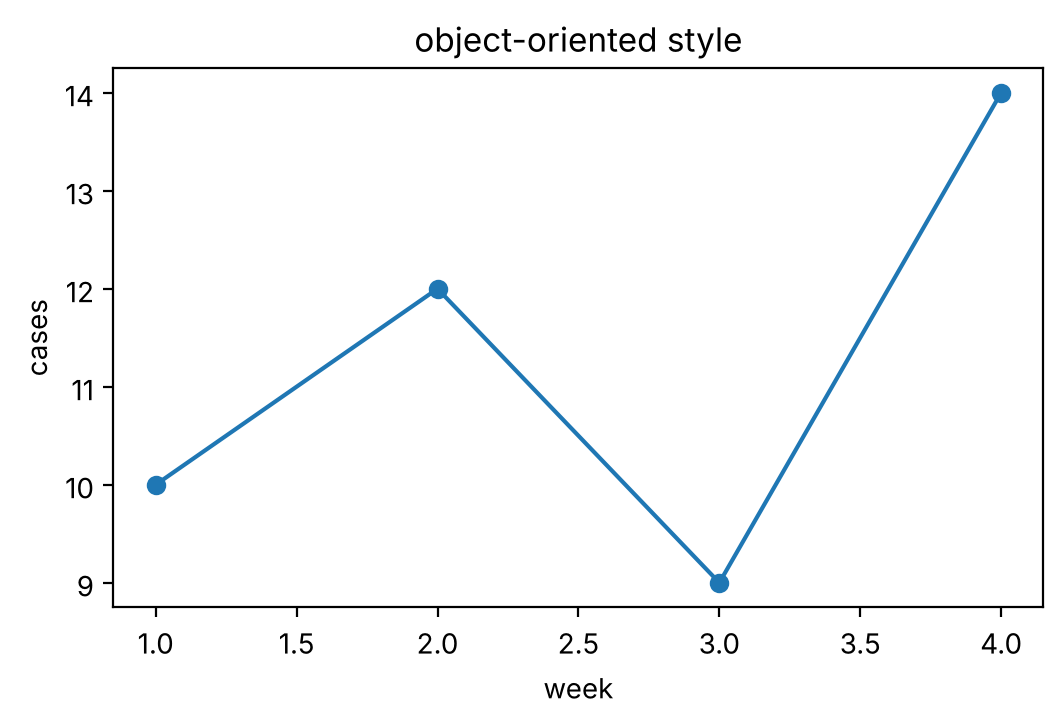

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([1, 2, 3, 4], [10, 12, 9, 14], marker="o")
ax.set_title("object-oriented style")
ax.set_xlabel("week")
ax.set_ylabel("cases")
plt.show()

The pyplot function `plt.xlabel` corresponds to the method `ax.set_xlabel`; most others follow the
`set_` pattern: `set_title`, `set_xlim`, `set_ylim`, `set_xticks`.

## pandas plotting

pandas has a `.plot` method that calls Matplotlib for you and returns an Axes you can then customise.

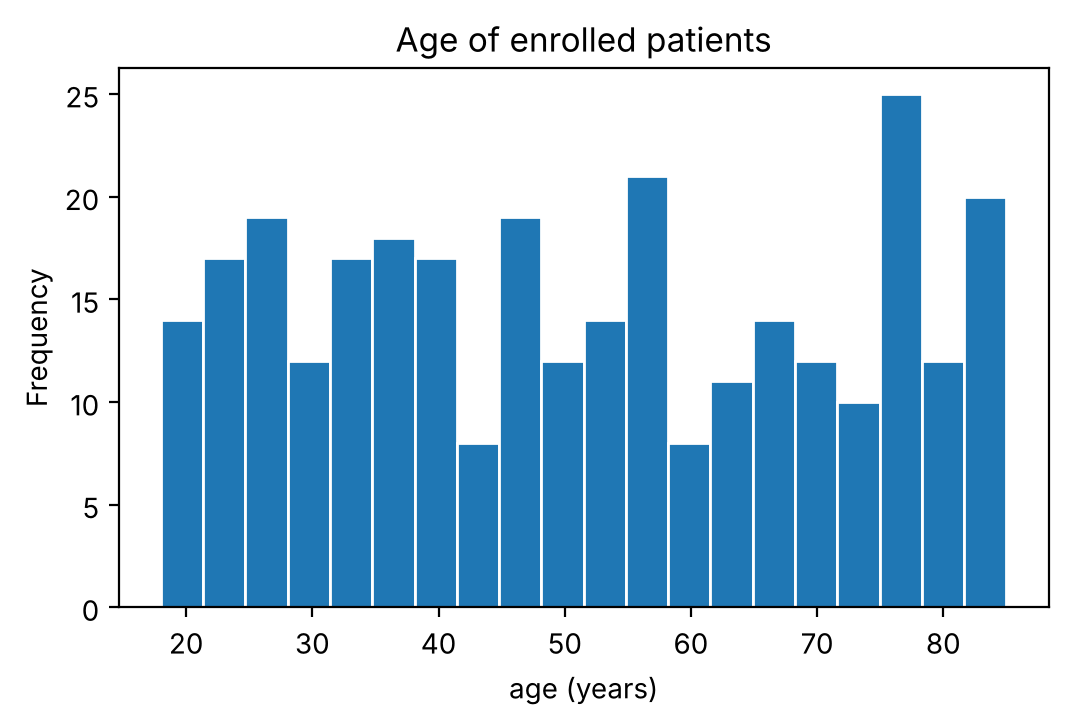

In [6]:
patients = pd.read_csv(RAW + "patients.csv")
ax = patients["age"].plot.hist(bins=20, edgecolor="white", figsize=(6, 3.5))
ax.set_xlabel("age (years)")
ax.set_title("Age of enrolled patients")
plt.show()

In notebooks, `plt.show()` is optional but keeps the output clean (no `<Axes ...>` text line). In
scripts, it is what opens the window.

## Practise

Exercises for this folder are in `exercises/Matplotlib_Exercises.ipynb`.

## Further reading

- [Matplotlib user guide](https://matplotlib.org/stable/users/index.html)
- [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html)
- [Parts of a figure](https://matplotlib.org/stable/users/explain/quick_start.html#parts-of-a-figure)
- [Claus O. Wilke, Fundamentals of Data Visualization](https://clauswilke.com/dataviz/)